# Aula 7.5 — Desafio: otimizando um modelo no dataset Wine

**Dataset:** `load_wine`, com 178 vinhos, 13 medidas químicas e 3 classes (três produtores da mesma região da Itália). **Métrica: acurácia.**


- o mesmo split treino/teste (o teste fica guardado até o fim);
- os mesmos 5 folds de validação cruzada;
- o mesmo orçamento de **12 configurações**;
- a mesma regra de desempate.

| Etapa | O que faz |
|---|---|
| 01–03 | carregar, explorar e dividir |
| 04 | definir o espaço de busca |
| 05–07 | Grid Search, Random Search e Optuna (TPE + MedianPruner) |
| 08–10 | comparar resultados, avaliar no teste e comparar tempos |
| 11–12 | explicar as diferenças e concluir |

## 01 · Carregar o dataset

In [ ]:

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="IProgress not found")   # aviso de barra de progresso, sem efeito no resultado
import optuna
import scipy, sklearn

from optuna.trial import TrialState
from scipy.stats import randint, loguniform
from sklearn.datasets import load_wine
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay)

optuna.logging.set_verbosity(optuna.logging.WARNING)
print("NumPy:", np.__version__, "| Pandas:", pd.__version__, "| SciPy:", scipy.__version__,
      "| scikit-learn:", sklearn.__version__, "| Optuna:", optuna.__version__)

dados = load_wine()
X = pd.DataFrame(dados.data, columns=dados.feature_names)
y = dados.target
print()
print("X:", X.shape, "| classes:", dict(zip(dados.target_names, np.bincount(y))))

NumPy: 2.5.3 | Pandas: 3.0.5 | SciPy: 1.18.1 | scikit-learn: 1.9.1 | Optuna: 5.1.0

X: (178, 13) | classes: {np.str_('class_0'): np.int64(59), np.str_('class_1'): np.int64(71), np.str_('class_2'): np.int64(48)}


## 02 · Explorar os dados

In [2]:
print("Valores ausentes:", X.isna().sum().sum())
print()
print(X.describe().T[["mean", "std", "min", "max"]].round(2))

Valores ausentes: 0

                                mean     std     min      max
alcohol                        13.00    0.81   11.03    14.83
malic_acid                      2.34    1.12    0.74     5.80
ash                             2.37    0.27    1.36     3.23
alcalinity_of_ash              19.49    3.34   10.60    30.00
magnesium                      99.74   14.28   70.00   162.00
total_phenols                   2.30    0.63    0.98     3.88
flavanoids                      2.03    1.00    0.34     5.08
nonflavanoid_phenols            0.36    0.12    0.13     0.66
proanthocyanins                 1.59    0.57    0.41     3.58
color_intensity                 5.06    2.32    1.28    13.00
hue                             0.96    0.23    0.48     1.71
od280/od315_of_diluted_wines    2.61    0.71    1.27     4.00
proline                       746.89  314.91  278.00  1680.00


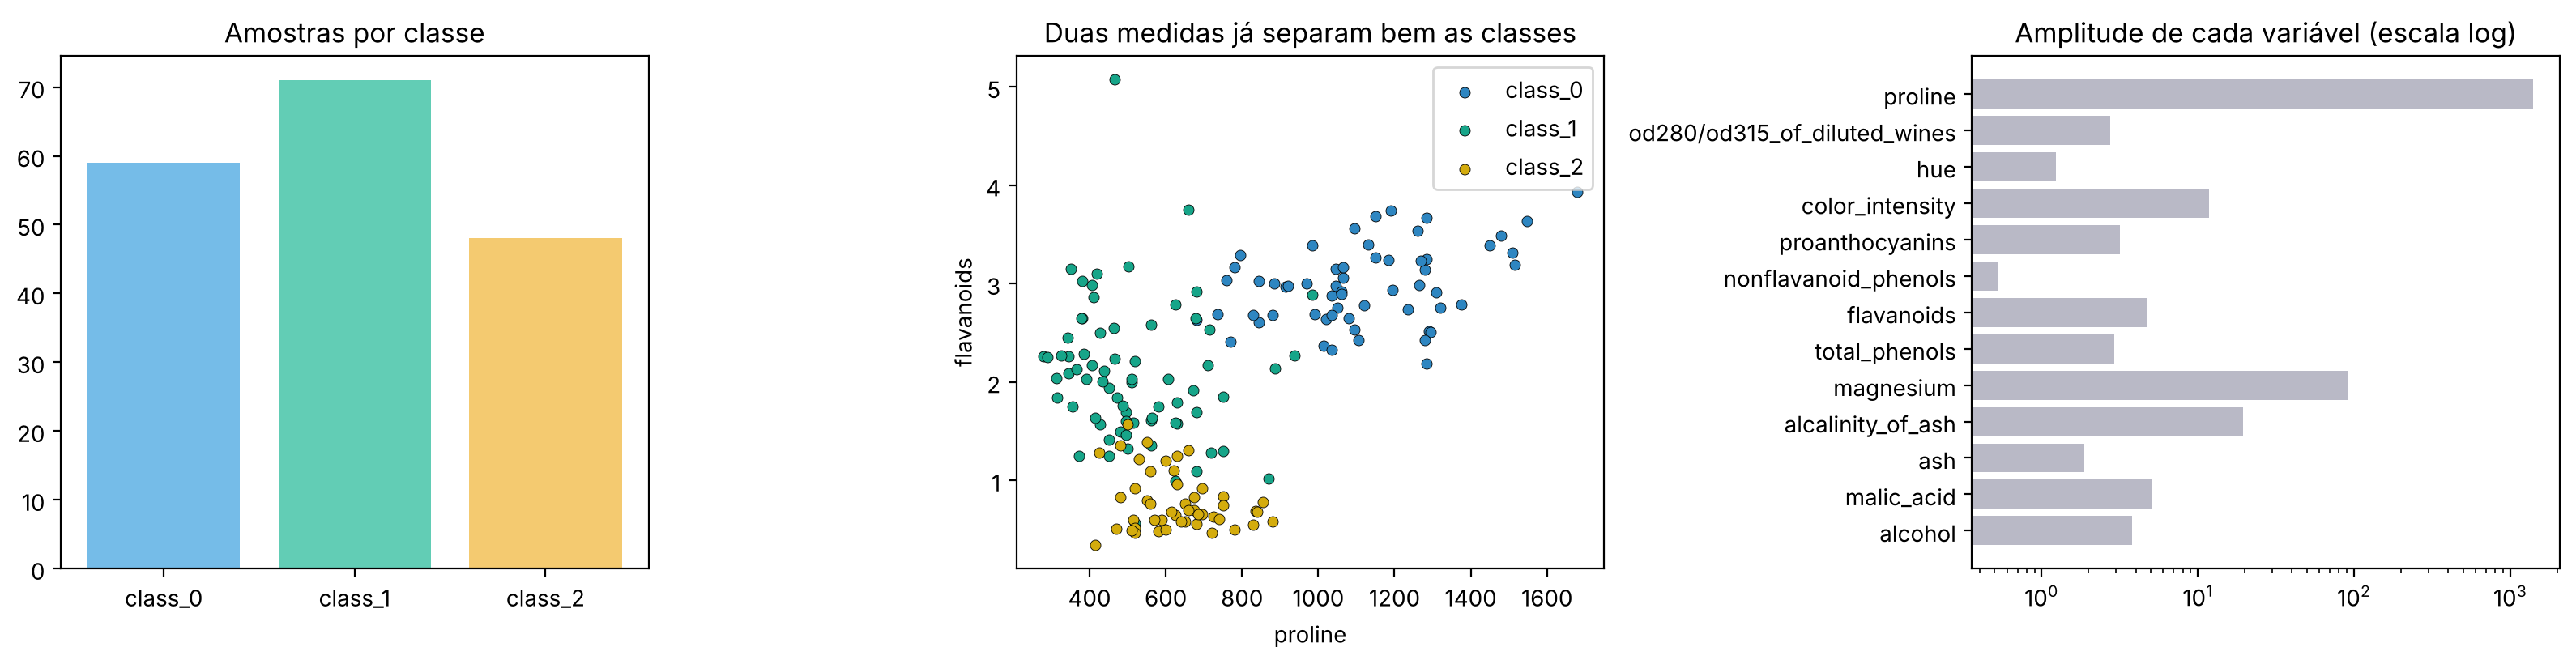

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].bar(dados.target_names, np.bincount(y), color=["#75BCE8", "#62CDB5", "#F4CA70"])
axes[0].set_title("Amostras por classe")

cores = ["#2E86C1", "#17A589", "#D4AC0D"]
for c in range(3):
    axes[1].scatter(X.loc[y == c, "proline"], X.loc[y == c, "flavanoids"], s=22,
                    color=cores[c], edgecolors="k", linewidths=0.3, label=dados.target_names[c])
axes[1].set_xlabel("proline"); axes[1].set_ylabel("flavanoids")
axes[1].set_title("Duas medidas já separam bem as classes"); axes[1].legend()

axes[2].barh(X.columns, X.max() - X.min(), color="#B9B9C6")
axes[2].set_xscale("log"); axes[2].set_title("Amplitude de cada variável (escala log)")
plt.tight_layout(); plt.show()

As escalas são muito diferentes: `proline` vai até 1.680, enquanto `hue` fica abaixo de 2. Para um **boosting de árvores isso não importa**, porque cada divisão compara uma variável com um limite. Por isso não usamos `StandardScaler`.

## 03 · Dividir treino e teste (80 / 20, estratificado)

O teste tem só 36 vinhos, então **cada erro no teste vale 2,8 p.p. de acurácia**. A validação cruzada usa **5 folds** fixos (a lista `splits`), e as três estratégias usam exatamente os mesmos.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print("Treino:", X_train.shape, np.bincount(y_train))
print("Teste: ", X_test.shape, np.bincount(y_test))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
splits = list(cv.split(X_train, y_train))
for i, (tr, va) in enumerate(splits, 1):
    print(f"Fold {i}: ajuste={len(tr)}, validação={len(va)}")

ARVORES = 150
modelo_base = GradientBoostingClassifier(n_estimators=ARVORES, random_state=42)

# referências sem otimização
for nome, m in [("Dummy (classe mais frequente)", DummyClassifier(strategy="most_frequent")),
                ("Gradient Boosting padrão", modelo_base)]:
    r = cross_validate(m, X_train, y_train, cv=splits, scoring="accuracy")
    print(f"{nome}: acurácia CV = {r['test_score'].mean():.4f}")

Treino: (142, 13) [47 57 38]
Teste:  (36, 13) [12 14 10]
Fold 1: ajuste=113, validação=29
Fold 2: ajuste=113, validação=29
Fold 3: ajuste=114, validação=28
Fold 4: ajuste=114, validação=28
Fold 5: ajuste=114, validação=28
Dummy (classe mais frequente): acurácia CV = 0.4012


Gradient Boosting padrão: acurácia CV = 0.9232


## 04 · Definir o espaço de busca

Usamos o mesmo modelo e os mesmos três hiperparâmetros nas três estratégias. A diferença é **como** cada uma percorre o espaço.

| Hiperparâmetro | Grid (12 pontos fixos) | Random e Optuna (distribuição) |
|---|---|---|
| `max_depth` | 1, 2, 3 | inteiro de 1 a 3 |
| `learning_rate` | 0,03 e 0,1 | contínuo de 0,01 a 0,3, **escala log** |
| `min_samples_leaf` | 1 e 5 | inteiro de 1 a 5 |

`GradientBoostingClassifier` com 3 classes treina **3 árvores por etapa**, uma para cada classe (perda multinomial). Então 150 etapas são 450 árvores.

**Critério de escolha:** maior acurácia média nos 5 folds. Com só ~28 vinhos por fold, a acurácia empata com frequência. Por isso, **em caso de empate, vence o menor log loss** (a melhor probabilidade). A mesma regra vale para as três estratégias.

In [5]:
param_grid = {"max_depth": [1, 2, 3],
              "learning_rate": [0.03, 0.10],
              "min_samples_leaf": [1, 5]}

param_dist = {"max_depth": randint(1, 4),              # 1, 2, 3 (o limite superior é exclusivo)
              "learning_rate": loguniform(0.01, 0.3),
              "min_samples_leaf": randint(1, 6)}       # 1 a 5

ORCAMENTO = 12
SCORING = {"acc": "accuracy", "logloss": "neg_log_loss"}

def melhor_da_busca(busca):
    r = pd.DataFrame(busca.cv_results_)
    r = r.sort_values(["mean_test_acc", "mean_test_logloss"], ascending=[False, False])
    linha = r.iloc[0]
    return linha["params"], linha["mean_test_acc"], -linha["mean_test_logloss"], r

print("Configurações da grade:", int(np.prod([len(v) for v in param_grid.values()])))

Configurações da grade: 12


## 05 · Grid Search

In [6]:
grid = GridSearchCV(modelo_base, param_grid, scoring=SCORING, cv=splits,
                    refit=False, n_jobs=1, error_score="raise")
t0 = time.perf_counter(); grid.fit(X_train, y_train); tempo_grid = time.perf_counter() - t0

params_grid, acc_grid, ll_grid, res_grid = melhor_da_busca(grid)
print("Melhores parâmetros:", params_grid)
print(f"Acurácia CV: {acc_grid:.4f} | log loss CV: {ll_grid:.4f} | tempo: {tempo_grid:.2f} s")
print()
print(res_grid[["params", "mean_test_acc", "std_test_acc", "mean_test_logloss"]]
      .assign(mean_test_logloss=lambda d: -d["mean_test_logloss"]).round(4).to_string(index=False))

Melhores parâmetros: {'learning_rate': 0.1, 'max_depth': 1, 'min_samples_leaf': 1}
Acurácia CV: 0.9719 | log loss CV: 0.0732 | tempo: 17.57 s

                                                        params  mean_test_acc  std_test_acc  mean_test_logloss
 {'learning_rate': 0.1, 'max_depth': 1, 'min_samples_leaf': 1}         0.9719        0.0141             0.0732
 {'learning_rate': 0.1, 'max_depth': 1, 'min_samples_leaf': 5}         0.9719        0.0141             0.0763
{'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 5}         0.9653        0.0378             0.1062
{'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 1}         0.9584        0.0402             0.1487
{'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 5}         0.9581        0.0506             0.1115
 {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 5}         0.9581        0.0337             0.1620
 {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 1}         0.9581   

## 06 · Random Search (12 sorteios)

In [7]:
rand = RandomizedSearchCV(modelo_base, param_dist, n_iter=ORCAMENTO, scoring=SCORING, cv=splits,
                          random_state=42, refit=False, n_jobs=1, error_score="raise")
t0 = time.perf_counter(); rand.fit(X_train, y_train); tempo_random = time.perf_counter() - t0

params_rand, acc_rand, ll_rand, res_rand = melhor_da_busca(rand)
print("Melhores parâmetros:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in params_rand.items()})
print(f"Acurácia CV: {acc_rand:.4f} | log loss CV: {ll_rand:.4f} | tempo: {tempo_random:.2f} s")
print()
print(res_rand[["params", "mean_test_acc", "std_test_acc", "mean_test_logloss"]]
      .assign(mean_test_logloss=lambda d: -d["mean_test_logloss"]).round(4).to_string(index=False))

Melhores parâmetros: {'learning_rate': np.float64(0.0281), 'max_depth': 2, 'min_samples_leaf': 5}
Acurácia CV: 0.9653 | log loss CV: 0.1074 | tempo: 15.38 s

                                                                        params  mean_test_acc  std_test_acc  mean_test_logloss
{'learning_rate': 0.028145092716060652, 'max_depth': 2, 'min_samples_leaf': 5}         0.9653        0.0378             0.1074
 {'learning_rate': 0.14180715647623926, 'max_depth': 1, 'min_samples_leaf': 2}         0.9650        0.0218             0.0750
 {'learning_rate': 0.08012737503998542, 'max_depth': 2, 'min_samples_leaf': 4}         0.9650        0.0218             0.1488
  {'learning_rate': 0.2708160864249968, 'max_depth': 2, 'min_samples_leaf': 2}         0.9650        0.0218             0.2297
 {'learning_rate': 0.04345454109729477, 'max_depth': 1, 'min_samples_leaf': 3}         0.9581        0.0337             0.1060
 {'learning_rate': 0.03672338759552654, 'max_depth': 1, 'min_samples_leaf': 3}  

## 07 · Optuna (TPE + MedianPruner)

- **Sampler TPE** (`seed=42`, 5 trials iniciais aleatórios): depois deles, propõe valores perto dos trials que foram bem.
- **MedianPruner:** a cada checkpoint (25, 50, 75, 100 e 150 etapas), compara a acurácia média dos 5 folds com a mediana dos trials anteriores **no mesmo checkpoint**. Se ficar abaixo, o trial é interrompido.
- `warm_start=True` acrescenta árvores sem recomeçar: chegar a 150 custa 150 etapas, não 25 + 50 + 75 + 100 + 150.

O valor reportado ao pruner é a acurácia, mas o log loss de cada trial também é guardado, para aplicar a mesma regra de desempate.

In [8]:
CHECKPOINTS = [25, 50, 75, 100, 150]

def objective(trial):
    params = {"max_depth": trial.suggest_int("max_depth", 1, 3),
              "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
              "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5)}
    modelos = [GradientBoostingClassifier(n_estimators=CHECKPOINTS[0], warm_start=True,
                                          random_state=42, **params) for _ in splits]
    for etapa in CHECKPOINTS:
        accs, lls = [], []
        for m, (tr, va) in zip(modelos, splits):
            m.set_params(n_estimators=etapa)
            m.fit(X_train.iloc[tr], y_train[tr])
            proba = m.predict_proba(X_train.iloc[va])
            accs.append(accuracy_score(y_train[va], proba.argmax(axis=1)))
            lls.append(log_loss(y_train[va], proba, labels=[0, 1, 2]))
        acc = float(np.mean(accs))
        trial.set_user_attr("ultimo_checkpoint", etapa)
        trial.set_user_attr("logloss", float(np.mean(lls)))
        trial.report(acc, step=etapa)
        if etapa < CHECKPOINTS[-1] and trial.should_prune():
            raise optuna.TrialPruned()
    return acc

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=5),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=50,
                                                               interval_steps=25, n_min_trials=3))
t0 = time.perf_counter(); study.optimize(objective, n_trials=ORCAMENTO, n_jobs=1); tempo_optuna = time.perf_counter() - t0

completos = [t for t in study.trials if t.state == TrialState.COMPLETE]
podados = [t for t in study.trials if t.state == TrialState.PRUNED]
melhor_trial = sorted(completos, key=lambda t: (-t.value, t.user_attrs["logloss"]))[0]
params_opt, acc_opt, ll_opt = melhor_trial.params, melhor_trial.value, melhor_trial.user_attrs["logloss"]

print("Melhores parâmetros:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in params_opt.items()})
print(f"Acurácia CV: {acc_opt:.4f} | log loss CV: {ll_opt:.4f} | tempo: {tempo_optuna:.2f} s")
print("Trials completos:", len(completos), "| interrompidos:", len(podados))
print()
print(pd.DataFrame([{"trial": t.number, "estado": t.state.name,
                     "acc (último checkpoint)": t.intermediate_values[t.user_attrs["ultimo_checkpoint"]],
                     "log loss": t.user_attrs["logloss"], "parou em": t.user_attrs["ultimo_checkpoint"],
                     **t.params} for t in study.trials]).round(4).to_string(index=False))

Melhores parâmetros: {'max_depth': 1, 'learning_rate': 0.1406, 'min_samples_leaf': 5}
Acurácia CV: 0.9719 | log loss CV: 0.0749 | tempo: 14.68 s
Trials completos: 9 | interrompidos: 3

 trial   estado  acc (último checkpoint)  log loss  parou em  max_depth  learning_rate  min_samples_leaf
     0 COMPLETE                   0.9581    0.2226       150          2         0.2537                 4
     1 COMPLETE                   0.9515    0.1908       150          2         0.0170                 1
     2 COMPLETE                   0.9650    0.0835       150          1         0.1903                 4
     3 COMPLETE                   0.9372    0.2449       150          3         0.0107                 5
     4 COMPLETE                   0.9022    0.2208       150          3         0.0206                 1
     5 COMPLETE                   0.9719    0.0749       150          1         0.1406                 5
     6 COMPLETE                   0.9650    0.0760       150          1         

## 08 · Comparar os resultados da busca

In [9]:
estimadores_grid = len(res_grid) * len(splits) * ARVORES
estimadores_rand = len(res_rand) * len(splits) * ARVORES
estimadores_opt = sum(t.user_attrs["ultimo_checkpoint"] for t in study.trials) * len(splits)

busca = pd.DataFrame({
    "Estratégia": ["Grid Search", "Random Search", "Optuna"],
    "Melhores parâmetros": [params_grid, params_rand, params_opt],
    "Acurácia CV": [acc_grid, acc_rand, acc_opt],
    "Log loss CV": [ll_grid, ll_rand, ll_opt],
    "Configurações": [len(res_grid), len(res_rand), len(study.trials)],
    "Interrompidas": [0, 0, len(podados)],
    "Etapas de boosting treinadas": [estimadores_grid, estimadores_rand, estimadores_opt],
    "Busca (s)": [tempo_grid, tempo_random, tempo_optuna],
}).set_index("Estratégia")
busca["Melhores parâmetros"] = busca["Melhores parâmetros"].apply(
    lambda p: ", ".join(f"{k}={round(v, 3) if isinstance(v, float) else v}" for k, v in sorted(p.items())))
print(busca.round(4).to_string())

                                                Melhores parâmetros  Acurácia CV  Log loss CV  Configurações  Interrompidas  Etapas de boosting treinadas  Busca (s)
Estratégia                                                                                                                                                          
Grid Search      learning_rate=0.1, max_depth=1, min_samples_leaf=1       0.9719       0.0732             12              0                          9000    17.5705
Random Search  learning_rate=0.028, max_depth=2, min_samples_leaf=5       0.9653       0.1074             12              0                          9000    15.3773
Optuna         learning_rate=0.141, max_depth=1, min_samples_leaf=5       0.9719       0.0749             12              3                          7500    14.6793


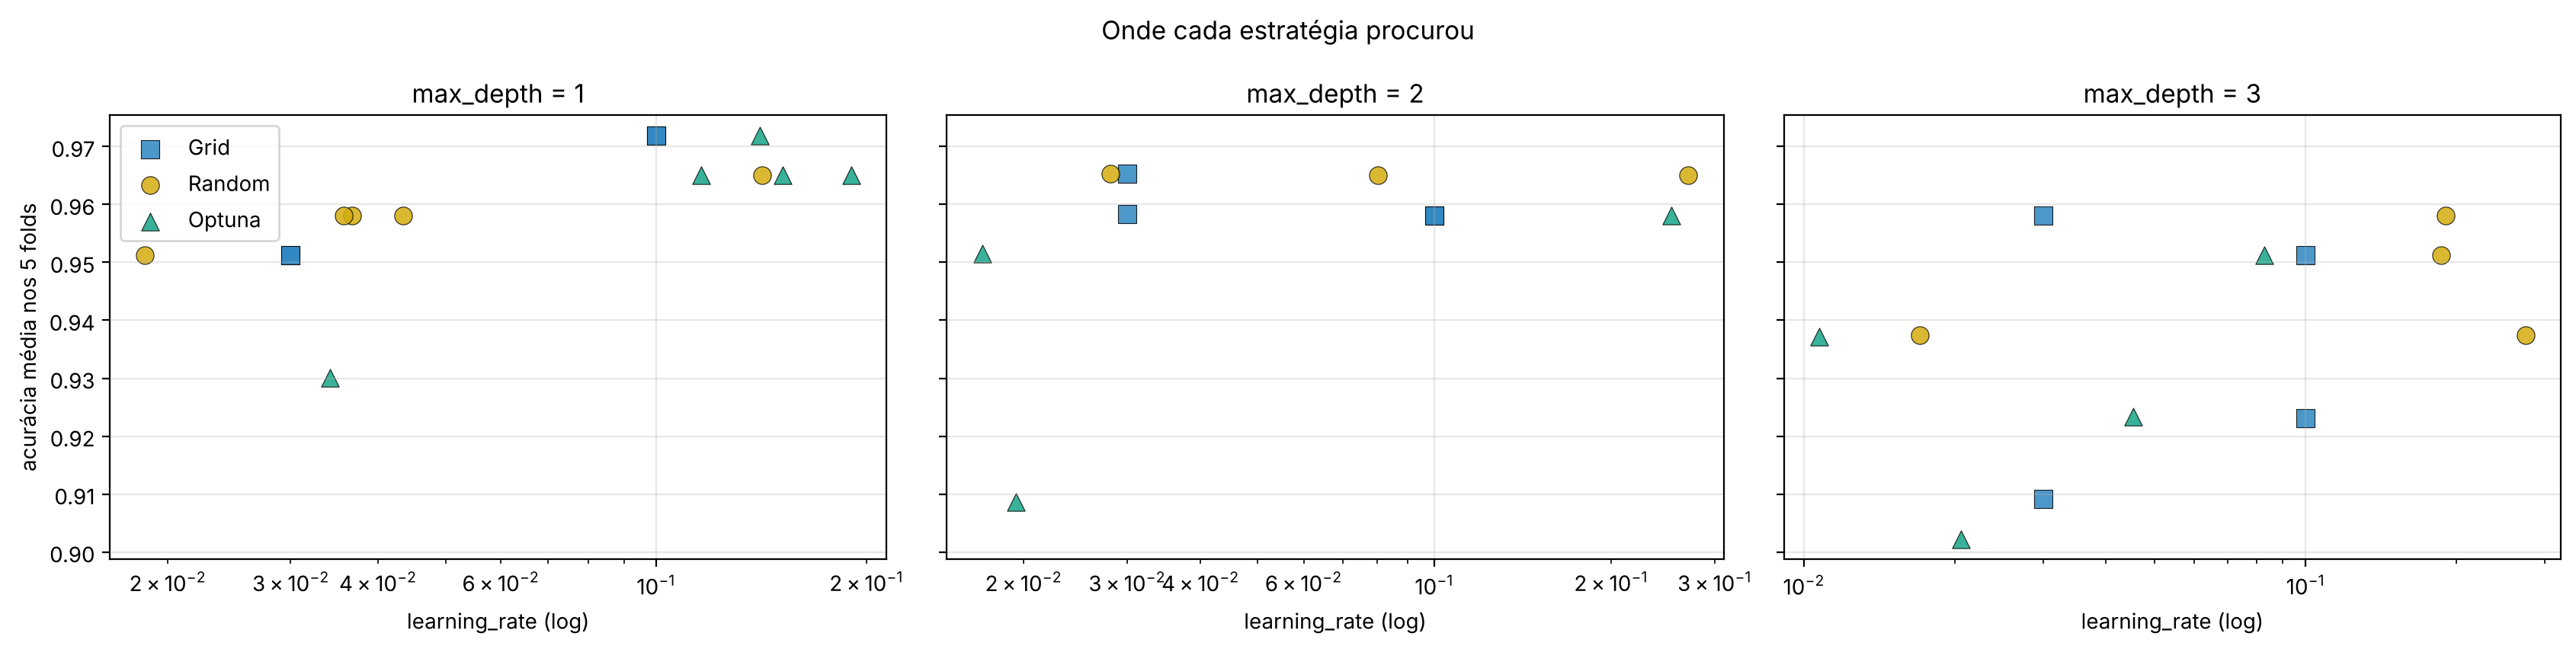

In [10]:
# onde cada estratégia procurou: learning_rate × acurácia CV, por max_depth
pontos = pd.concat([
    pd.DataFrame({"estrategia": "Grid", "lr": res_grid["param_learning_rate"].astype(float),
                  "depth": res_grid["param_max_depth"].astype(int), "acc": res_grid["mean_test_acc"]}),
    pd.DataFrame({"estrategia": "Random", "lr": res_rand["param_learning_rate"].astype(float),
                  "depth": res_rand["param_max_depth"].astype(int), "acc": res_rand["mean_test_acc"]}),
    pd.DataFrame({"estrategia": "Optuna", "lr": [t.params["learning_rate"] for t in study.trials],
                  "depth": [t.params["max_depth"] for t in study.trials],
                  "acc": [t.intermediate_values[t.user_attrs["ultimo_checkpoint"]] for t in study.trials]}),
])
estilo = {"Grid": ("s", "#2E86C1"), "Random": ("o", "#D4AC0D"), "Optuna": ("^", "#17A589")}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
for ax, d in zip(axes, [1, 2, 3]):
    for est, (marca, cor) in estilo.items():
        p = pontos[(pontos["estrategia"] == est) & (pontos["depth"] == d)]
        ax.scatter(p["lr"], p["acc"], marker=marca, s=70, color=cor, edgecolors="k",
                   linewidths=0.4, alpha=0.85, label=est)
    ax.set_xscale("log"); ax.set_title(f"max_depth = {d}"); ax.set_xlabel("learning_rate (log)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("acurácia média nos 5 folds"); axes[0].legend()
plt.suptitle("Onde cada estratégia procurou"); plt.tight_layout(); plt.show()

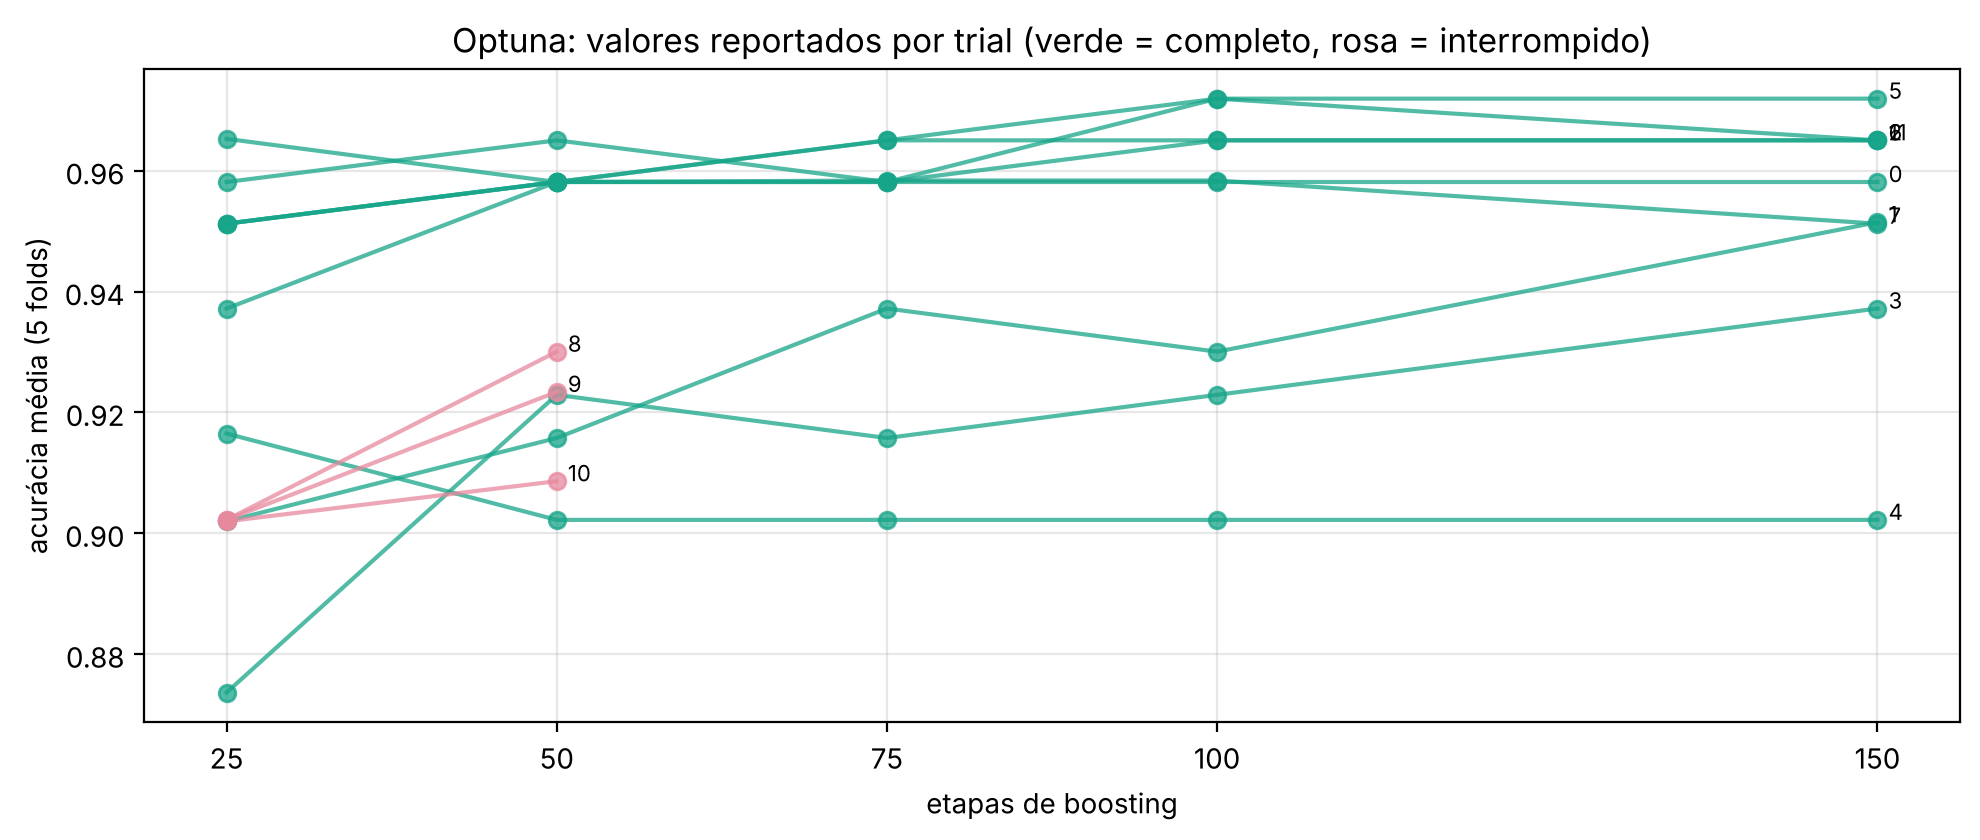

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.3))
for t in study.trials:
    passos = sorted(t.intermediate_values)
    cor = "#E8899E" if t.state == TrialState.PRUNED else "#17A589"
    ax.plot(passos, [t.intermediate_values[s] for s in passos], "o-", color=cor, alpha=0.75)
    ax.annotate(str(t.number), (passos[-1], t.intermediate_values[passos[-1]]),
                textcoords="offset points", xytext=(4, 0), fontsize=8)
ax.set_xticks(CHECKPOINTS); ax.set_xlabel("etapas de boosting"); ax.set_ylabel("acurácia média (5 folds)")
ax.set_title("Optuna: valores reportados por trial (verde = completo, rosa = interrompido)")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 09 · Avaliar os melhores modelos no teste (uma única vez)

Cada estratégia tem a sua configuração escolhida retreinada com **todo o treino** (150 etapas) e avaliada no teste.

                         Acurácia teste  Erros (de 36)  F1 macro  Log loss teste
Estratégia                                                                      
Grid Search                      1.0000              0    1.0000          0.0246
Random Search                    0.9722              1    0.9710          0.0788
Optuna                           0.9722              1    0.9743          0.0344
Sem otimização (padrão)          0.9444              2    0.9453          0.4658


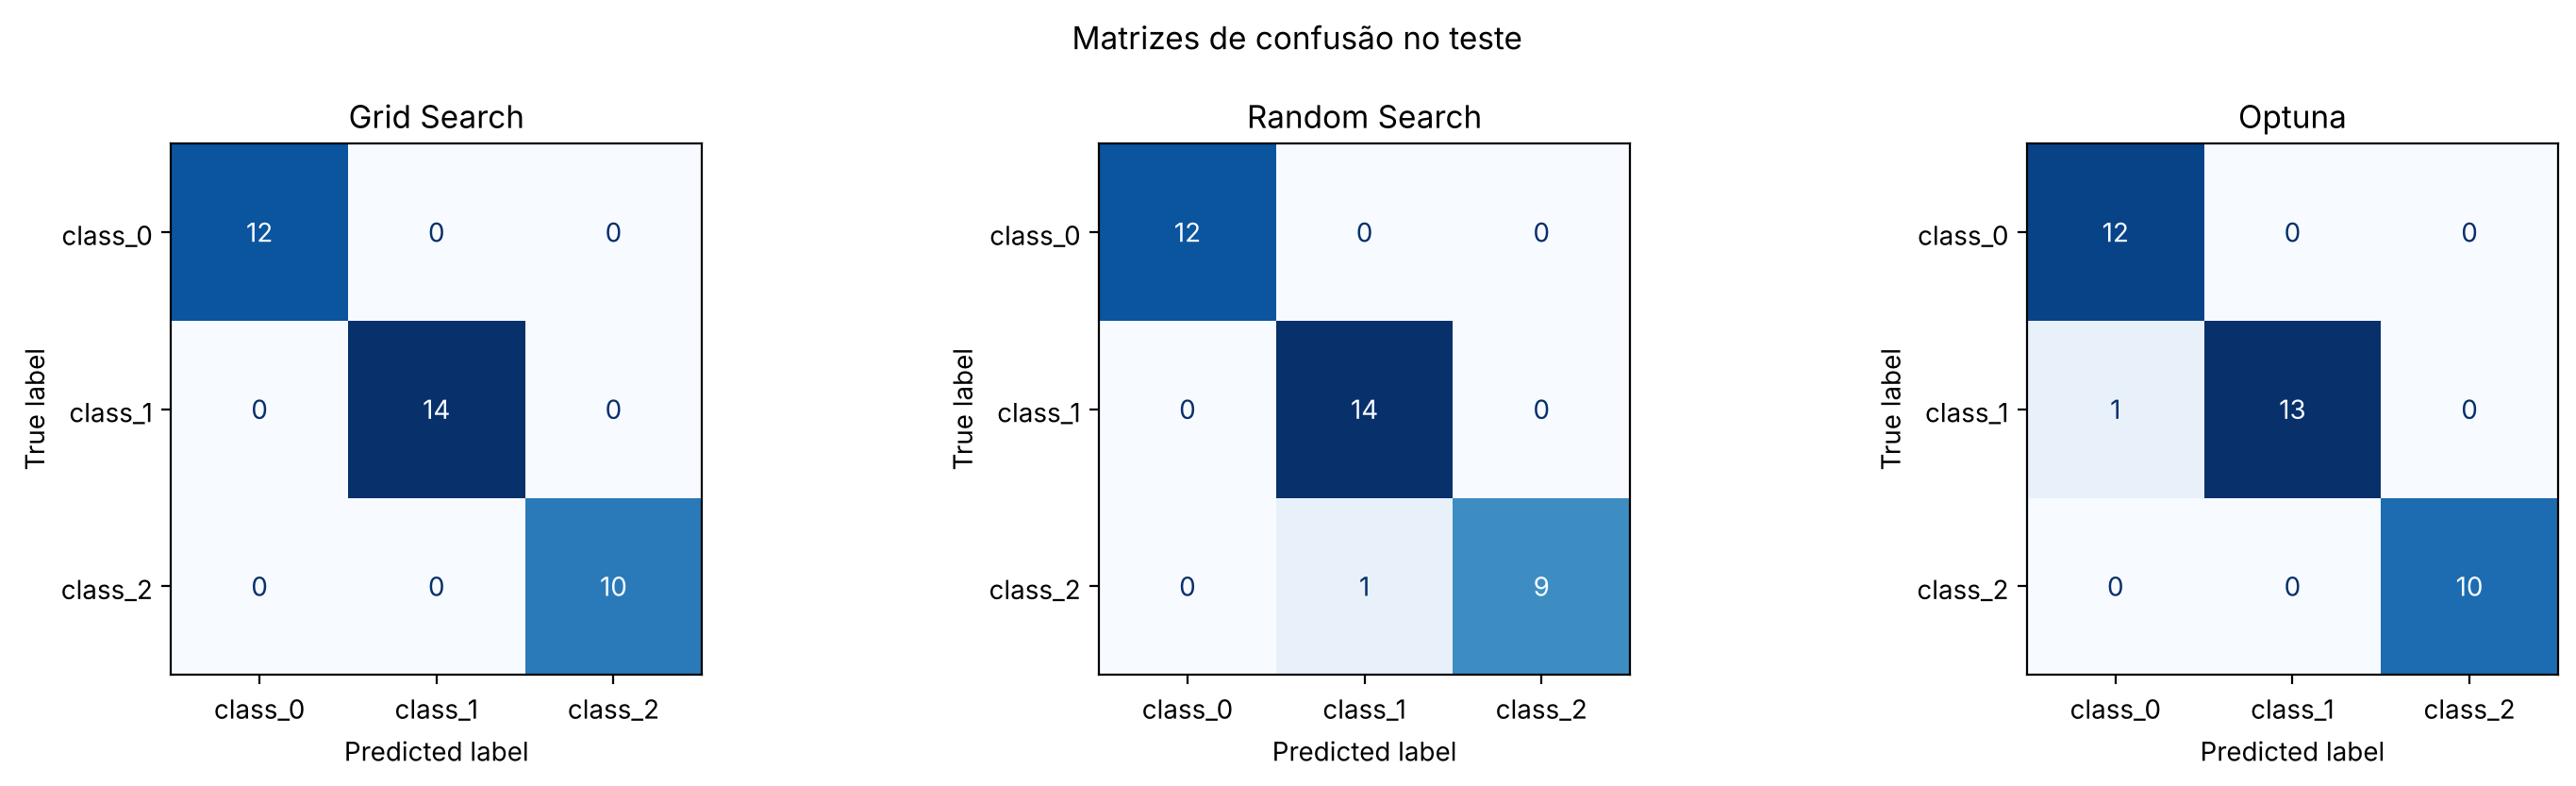

In [12]:
escolhas = {"Grid Search": params_grid, "Random Search": params_rand, "Optuna": params_opt}
finais, tempo_final, linhas, matrizes = {}, {}, [], {}
for nome, p in escolhas.items():
    m = GradientBoostingClassifier(n_estimators=ARVORES, random_state=42, **p)
    t0 = time.perf_counter(); m.fit(X_train, y_train); tempo_final[nome] = time.perf_counter() - t0
    proba = m.predict_proba(X_test); pred = proba.argmax(axis=1)
    matrizes[nome] = confusion_matrix(y_test, pred, labels=[0, 1, 2])
    linhas.append({"Estratégia": nome,
                   "Acurácia teste": accuracy_score(y_test, pred),
                   "Erros (de 36)": int((pred != y_test).sum()),
                   "F1 macro": f1_score(y_test, pred, average="macro"),
                   "Log loss teste": log_loss(y_test, proba, labels=[0, 1, 2])})

padrao = modelo_base.fit(X_train, y_train)
proba = padrao.predict_proba(X_test); pred = proba.argmax(axis=1)
linhas.append({"Estratégia": "Sem otimização (padrão)", "Acurácia teste": accuracy_score(y_test, pred),
               "Erros (de 36)": int((pred != y_test).sum()), "F1 macro": f1_score(y_test, pred, average="macro"),
               "Log loss teste": log_loss(y_test, proba, labels=[0, 1, 2])})
teste = pd.DataFrame(linhas).set_index("Estratégia")
print(teste.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (nome, cm) in zip(axes, matrizes.items()):
    ConfusionMatrixDisplay(cm, display_labels=dados.target_names).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nome)
plt.suptitle("Matrizes de confusão no teste"); plt.tight_layout(); plt.show()

## 10 · Comparar os tempos

               Busca (s)  Ajuste final (s)  Etapas treinadas  s por 1.000 etapas
Grid Search       17.571             0.273              9000               1.952
Random Search     15.377             0.302              9000               1.709
Optuna            14.679             0.225              7500               1.957


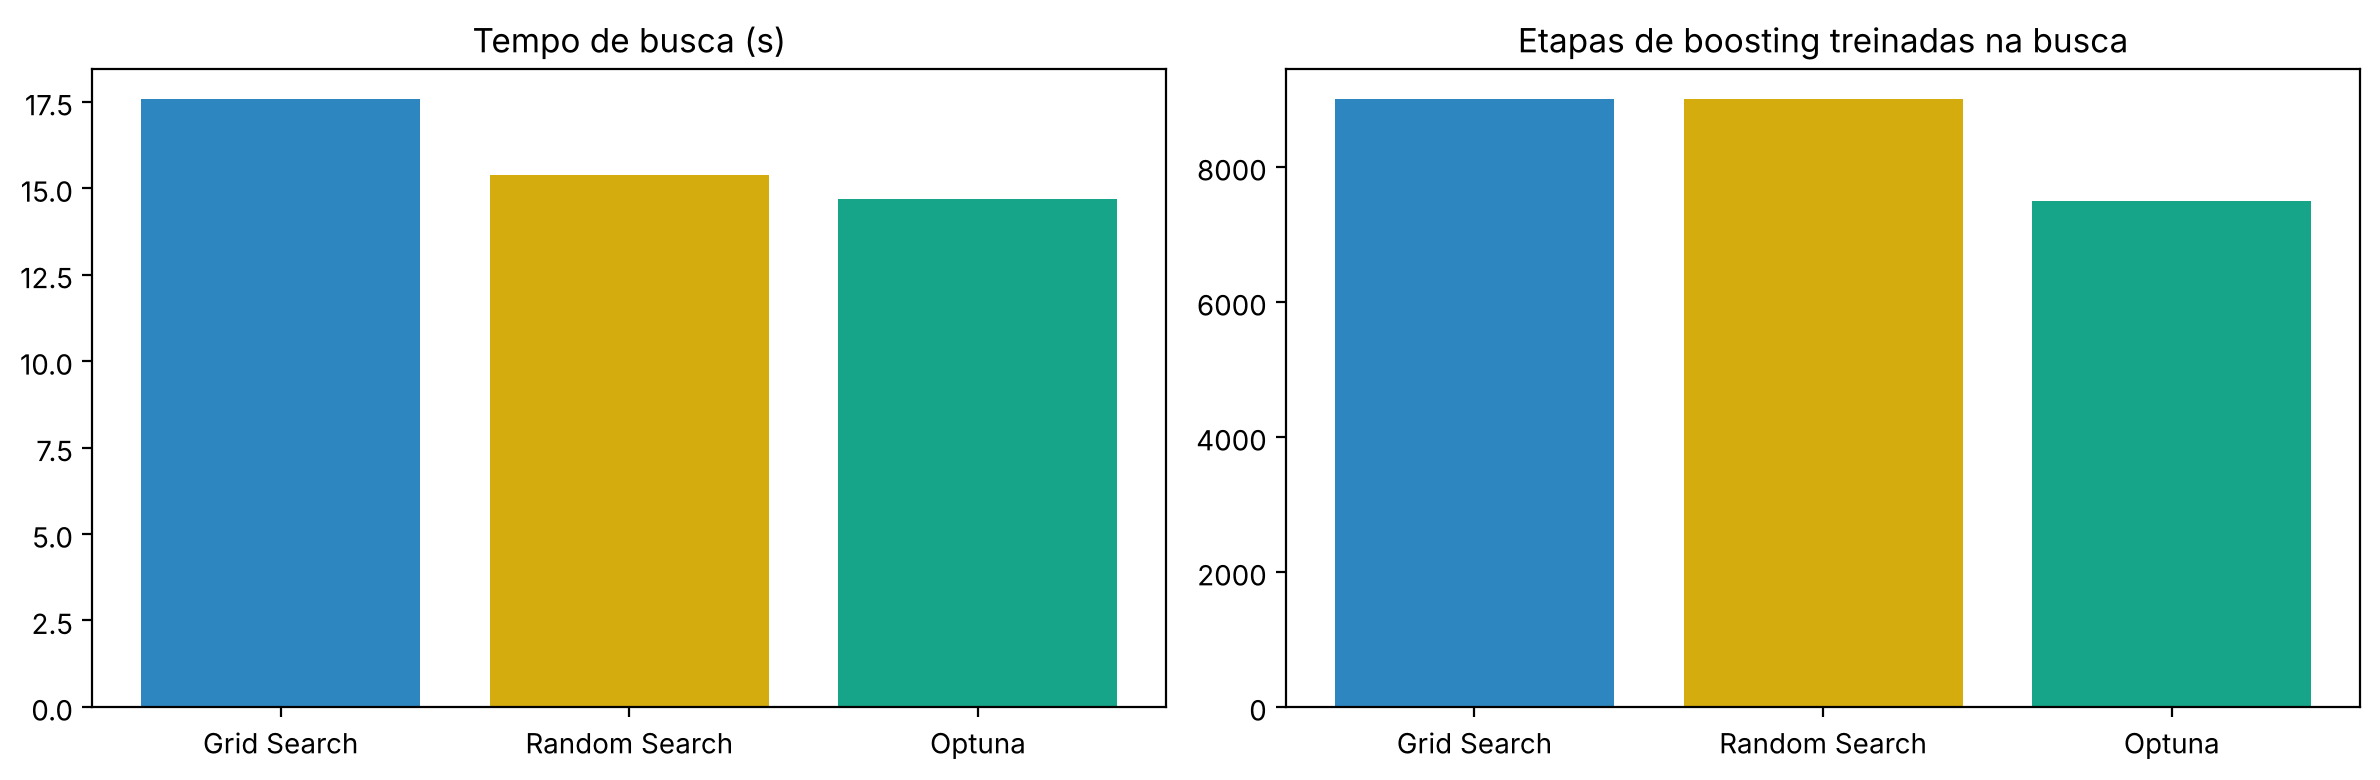

In [13]:
tempos = pd.DataFrame({"Busca (s)": [tempo_grid, tempo_random, tempo_optuna],
                       "Ajuste final (s)": [tempo_final[n] for n in escolhas],
                       "Etapas treinadas": [estimadores_grid, estimadores_rand, estimadores_opt]},
                      index=list(escolhas))
tempos["s por 1.000 etapas"] = 1000 * tempos["Busca (s)"] / tempos["Etapas treinadas"]
print(tempos.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(tempos.index, tempos["Busca (s)"], color=["#2E86C1", "#D4AC0D", "#17A589"])
axes[0].set_title("Tempo de busca (s)")
axes[1].bar(tempos.index, tempos["Etapas treinadas"], color=["#2E86C1", "#D4AC0D", "#17A589"])
axes[1].set_title("Etapas de boosting treinadas na busca")
plt.tight_layout(); plt.show()

## 11 e 12 · Explicar as diferenças e concluir

### Resumo dos números

| Estratégia | Configuração escolhida | Acurácia CV | Log loss CV | Etapas treinadas | Acurácia teste | Log loss teste |
|---|---|---|---|---|---|---|
| Sem otimização | padrão (`max_depth=3`, `lr=0.1`, `leaf=1`) | 0,923 | — | — | 0,944 (2 erros) | 0,466 |
| Grid Search | `max_depth=1`, `lr=0.1`, `leaf=1` | **0,972** | **0,073** | 9.000 | **1,000 (0 erros)** | **0,025** |
| Random Search | `max_depth=2`, `lr=0.028`, `leaf=5` | 0,965 | 0,107 | 9.000 | 0,972 (1 erro) | 0,079 |
| Optuna (TPE + pruning) | `max_depth=1`, `lr=0.141`, `leaf=5` | **0,972** | 0,075 | **7.500** | 0,972 (1 erro) | 0,034 |

### 11 · Por que os resultados foram diferentes

**1. A otimização valeu a pena.** O modelo padrão (`max_depth=3`) teve acurácia de 92,3% na validação cruzada e **log loss de 0,47 no teste**: com árvores profundas para só 142 vinhos, ele fica confiante demais. As três estratégias encontraram árvores **rasas** (`max_depth` 1 ou 2) e subiram para 96,5% a 97,2% na CV. O ganho maior foi no log loss do teste, que caiu de 0,47 para 0,02 a 0,08.

**2. A melhor região era "árvores de 1 nível com learning rate em torno de 0,1".** O Grid e o Optuna chegaram nela (acurácia CV de 0,972). O gráfico "onde cada estratégia procurou" mostra isso: com `max_depth=1`, os pontos de `learning_rate` entre 0,1 e 0,2 ficam no topo; com `max_depth=3`, a acurácia cai e varia muito entre os folds.

**3. O Grid teve sorte com a grade.** A combinação vencedora (`depth=1`, `lr=0.1`) estava entre os 12 pontos fixos. Se a grade tivesse só `lr` de 0,03 e 0,05, ele não chegaria lá. Esse é o limite do Grid: só testa o que foi listado.

**4. O Random Search achou a região, mas a regra de escolha não ficou com ela.** O sorteio testou `depth=1` com `lr=0.142` (acurácia de 0,9650 e log loss de 0,075, praticamente igual ao melhor do Grid). Mesmo assim, venceu `depth=2` com `lr=0.028`, que teve acurácia de **0,9653**: uma diferença de 0,0003, que vem só do fato de os folds terem 28 ou 29 vinhos. É um empate técnico decidido por arredondamento.

**5. O Optuna aprendeu com o histórico.** Os 5 primeiros trials foram sorteios iniciais (de `depth` 1 a 3). Depois deles, o TPE concentrou as propostas em `max_depth=1` com `lr` entre 0,12 e 0,19 (trials 5, 6 e 11), exatamente a melhor região. O **MedianPruner interrompeu 3 trials** na etapa 50 (os trials 8, 9 e 10), porque estavam abaixo da mediana. Isso economizou **1.500 das 9.000 etapas (17%)**.

**6. O tempo quase não mudou.** As três buscas levaram de 15 a 18 s, mais ou menos. O Optuna treinou 17% menos etapas, mas a cada checkpoint ele calcula as previsões dos 5 folds para reportar ao pruner, e esse custo extra comeu a economia. Num modelo mais caro (mais dados ou mais árvores), o pruning pesaria mais. Os tempos valem só para esta máquina e esta execução.

**7. O teste não separa as estratégias.** Com 36 vinhos no teste, **cada erro vale 2,8 p.p.** O Grid acertou os 36, e o Random e o Optuna erraram 1 cada. Essa diferença de um único vinho não permite dizer que uma estratégia é melhor que a outra. O próprio log loss do Optuna no teste (0,034) ficou muito perto do log loss do Grid (0,025).

### 12 · Qual estratégia foi mais interessante

Neste problema, **o Optuna foi a estratégia mais interessante**. Ele chegou à mesma acurácia de validação que o Grid (0,972) com 17% menos treino, sem precisar que alguém adivinhasse os valores certos da grade. Também dá para ver o TPE mudando de comportamento depois dos trials iniciais e o pruner cortando trials ruins. O **Grid** empatou porque a grade era pequena e bem escolhida. Com mais hiperparâmetros, ele explode: com 4 valores por hiperparâmetro, 5 deles já seriam 1.024 combinações. O **Random** é o mais simples e explorou bem o espaço contínuo de `learning_rate`, mas não aprende com os resultados, e aqui a escolha final foi decidida por uma diferença de 0,0003.

**Limitações:** o dataset é pequeno (142 vinhos no treino, 36 no teste), usamos um único split e uma semente, e o orçamento foi de só 12 configurações. A acurácia é uma métrica "em degraus" com poucos dados (cada vinho vale ~3,5 p.p. em um fold), o que causa muitos empates. Por isso usamos o log loss como desempate e o reportamos junto. Para uma conclusão robusta, seria preciso repetir o experimento com outras sementes e com validação cruzada repetida.